In [2]:
!pip install -q datasets transformers accelerate
import torch
print("GPU available:", torch.cuda.is_available(), "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU only (enable T4 GPU!)")

GPU available: True | Tesla T4


## 1. Imports, config and data

In [3]:
import json, numpy as np, pandas as pd, torch, matplotlib.pyplot as plt, seaborn as sns
from datasets import load_dataset, Dataset
from scipy.sparse import hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, precision_recall_fscore_support
from sklearn.model_selection import train_test_split
from transformers import (AutoModelForSequenceClassification, AutoTokenizer,
                          DataCollatorWithPadding, Trainer, TrainingArguments)

SEED, N, MAXLEN, MODEL = 42, 60000, 128, "distilbert-base-uncased"

# GLUE/QQP (Quora Question Pairs). label 1 = duplicate, 0 = not duplicate
ds = load_dataset("nyu-mll/glue", "qqp")
df = pd.concat([ds["train"].to_pandas(), ds["validation"].to_pandas()])
df = df[["question1", "question2", "label"]].dropna()
print("Total pairs:", len(df), "| duplicate share:", round(df.label.mean() * 100, 1), "%")
df = df.sample(N, random_state=SEED)  # random 60k sample so training fits on a T4 (splits below are stratified)
tr, tmp = train_test_split(df, test_size=0.2, stratify=df.label, random_state=SEED)
va, te = train_test_split(tmp, test_size=0.5, stratify=tmp.label, random_state=SEED)
print("Train/Val/Test:", len(tr), len(va), len(te))

README.md:   0%|          | 0.00/35.3k [00:00<?, ?B/s]

qqp/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 33.6MB            

qqp/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

qqp/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.73MB            

qqp/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

qqp/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/363846 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/40430 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/390965 [00:00<?, ? examples/s]

Total pairs: 404276 | duplicate share: 36.9 %
Train/Val/Test: 48000 6000 6000


In [4]:
def metrics(y, p):
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, labels=[0, 1], zero_division=0)
    return dict(accuracy=accuracy_score(y, p), precision=pr.tolist(), recall=rc.tolist(),
                f1=f1.tolist(), macro_f1=float(np.mean(f1)), confusion=confusion_matrix(y, p).tolist())

## 2. Baseline: TF-IDF difference/product features + Logistic Regression

In [5]:
tf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=200000).fit(pd.concat([tr.question1, tr.question2]))
def feats(d):
    a, b = tf.transform(d.question1), tf.transform(d.question2)
    return hstack([abs(a - b), a.multiply(b)]).tocsr()
base = metrics(te.label, LogisticRegression(max_iter=1000, C=4).fit(feats(tr), tr.label).predict(feats(te)))
print("Baseline accuracy:", round(base["accuracy"] * 100, 2), "%")

Baseline accuracy: 77.15 %


## 3. DistilBERT cross-encoder: `[CLS] question1 [SEP] question2 [SEP]`

In [6]:
tok = AutoTokenizer.from_pretrained(MODEL)
def prep(d):
    return Dataset.from_pandas(d.reset_index(drop=True)).map(
        lambda b: tok(b["question1"], b["question2"], truncation=True, max_length=MAXLEN), batched=True)
tr_ds, va_ds, te_ds = prep(tr), prep(va), prep(te)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/48000 [00:00<?, ? examples/s]

Map:   0%|          | 0/6000 [00:00<?, ? examples/s]

Map:   0%|          | 0/6000 [00:00<?, ? examples/s]

In [7]:
model = AutoModelForSequenceClassification.from_pretrained(MODEL, num_labels=2)
args = TrainingArguments(output_dir="dqd_out", num_train_epochs=2, learning_rate=2e-5,
                         per_device_train_batch_size=32, per_device_eval_batch_size=64,
                         fp16=torch.cuda.is_available(), seed=SEED, save_strategy="no", report_to="none")
trainer = Trainer(model=model, args=args, train_dataset=tr_ds, data_collator=DataCollatorWithPadding(tok))
trainer.train()

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
500,0.481124
1000,0.395040
1500,0.375950
2000,0.302423
2500,0.292578
3000,0.282989


TrainOutput(global_step=3000, training_loss=0.3550176391601563, metrics={'train_runtime': 208.3467, 'train_samples_per_second': 460.77, 'train_steps_per_second': 14.399, 'total_flos': 1688901378377088.0, 'train_loss': 0.3550176391601563, 'epoch': 2.0})

In [8]:
def evaluate(split_ds, y):
    logits = trainer.predict(split_ds).predictions
    return metrics(y, logits.argmax(1))
val, bert = evaluate(va_ds, va.label.values), evaluate(te_ds, te.label.values)

## 4. Results

In [9]:
res = dict(train=len(tr), val=len(va), test=len(te), baseline=base, distilbert=bert, validation=val)
json.dump(res, open("results.json", "w"), indent=2)
pct = lambda x: f"{x * 100:.2f}%"
print("DistilBERT TEST  acc:", pct(bert["accuracy"]), "| macro-F1:", pct(bert["macro_f1"]))
for i, n in enumerate(["Not Duplicate", "Duplicate"]):
    print(f"  {n:14s} P={pct(bert['precision'][i])} R={pct(bert['recall'][i])} F1={pct(bert['f1'][i])}")
print("Confusion matrix [[TN, FP],[FN, TP]]:", bert["confusion"])
print("Baseline acc:", pct(base["accuracy"]), "| Duplicate P/R/F1:",
      pct(base["precision"][1]), pct(base["recall"][1]), pct(base["f1"][1]))

DistilBERT TEST  acc: 84.37% | macro-F1: 83.58%
  Not Duplicate  P=90.57% R=84.02% F1=87.17%
  Duplicate      P=75.57% R=84.96% F1=79.99%
Confusion matrix [[TN, FP],[FN, TP]]: [[3187, 606], [332, 1875]]
Baseline acc: 77.15% | Duplicate P/R/F1: 72.02% 61.94% 66.60%


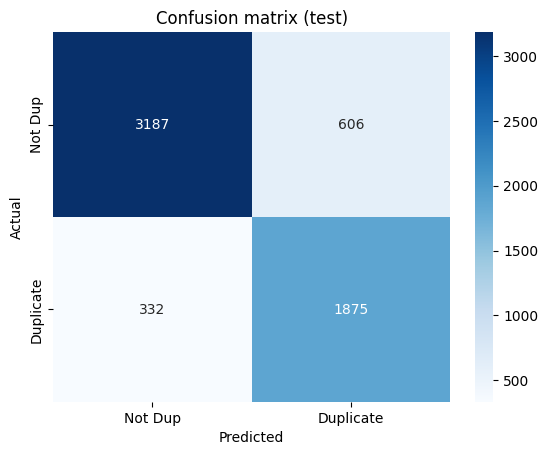

In [10]:
sns.heatmap(bert["confusion"], annot=True, fmt="d", cmap="Blues",
            xticklabels=["Not Dup", "Duplicate"], yticklabels=["Not Dup", "Duplicate"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion matrix (test)")
plt.savefig("confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Predict on new question pairs

In [11]:
trainer.save_model("dqd_model"); tok.save_pretrained("dqd_model")
def check(q1, q2):
    m = trainer.model.eval()
    x = tok(q1, q2, return_tensors="pt", truncation=True, max_length=MAXLEN).to(m.device)
    with torch.no_grad():
        p = torch.softmax(m(**x).logits, -1)[0]
    return ("Duplicate" if p[1] > p[0] else "Not Duplicate"), round(float(p.max()) * 100, 2)

for a, b in [("How do I learn Python fast?", "What is the quickest way to learn Python?"),
             ("How do I learn Python fast?", "What is the capital of France?"),
             ("How can I lose weight?", "How can I gain weight?")]:
    print(a, "|", b, "->", check(a, b))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

How do I learn Python fast? | What is the quickest way to learn Python? -> ('Duplicate', 92.54)
How do I learn Python fast? | What is the capital of France? -> ('Not Duplicate', 99.79)
How can I lose weight? | How can I gain weight? -> ('Duplicate', 92.08)


## 6. Give your own input (type two questions)
Run this cell, type any two questions when asked, and the model tells you if they are duplicates. Type `q` as the first question to stop.

In [12]:
while True:
    q1 = input("Question 1 (or 'q' to quit): ").strip()
    if q1.lower() == "q" or not q1:
        break
    q2 = input("Question 2: ").strip()
    if not q2:
        break
    label, conf = check(q1, q2)
    print(f"  -> {label} (confidence {conf}%)\n")

Question 1 (or 'q' to quit): q


## 7. Give your own data (upload a CSV file)
Upload a CSV with two columns named **question1** and **question2**. The model predicts for every row and gives you a results CSV to download.

In [13]:
from google.colab import files
import io

up = files.upload()                       # choose your CSV file
name = list(up.keys())[0]
inp = pd.read_csv(io.BytesIO(up[name]))
assert {"question1", "question2"} <= set(inp.columns), "CSV must have columns: question1, question2"
inp = inp.dropna(subset=["question1", "question2"]).reset_index(drop=True)

def predict_df(d, bs=64):
    m = trainer.model.eval()
    labels, confs = [], []
    for i in range(0, len(d), bs):
        part = d.iloc[i:i + bs]
        x = tok(part.question1.astype(str).tolist(), part.question2.astype(str).tolist(),
                return_tensors="pt", truncation=True, max_length=MAXLEN, padding=True).to(m.device)
        with torch.no_grad():
            p = torch.softmax(m(**x).logits, -1).cpu().numpy()
        labels += ["Duplicate" if r[1] > r[0] else "Not Duplicate" for r in p]
        confs += [round(float(r.max()) * 100, 2) for r in p]
    out = d.copy()
    out["prediction"], out["confidence_%"] = labels, confs
    return out

result = predict_df(inp)
result.to_csv("my_predictions.csv", index=False)
display(result.head(10))
files.download("my_predictions.csv")

IndexError: list index out of range

## 8. (Optional) Download training outputs

In [ ]:
files.download("results.json")
files.download("confusion_matrix.png")

# 9. from word file question detection

In [16]:
!pip install -q python-docx
import re, io, itertools
from docx import Document
from google.colab import files

THRESHOLD = 0.60   # duplicate probability needed to flag a pair (raise = stricter)

def extract_questions(file_bytes):
    doc = Document(io.BytesIO(file_bytes))
    lines = [p.text for p in doc.paragraphs]
    seen_cells = set()
    for t in doc.tables:                       # questions inside tables
        for row in t.rows:
            for c in row.cells:
                if id(c._tc) in seen_cells:    # skip merged cells counted twice
                    continue
                seen_cells.add(id(c._tc))
                lines += c.text.split("\n")
    qs = []
    for l in lines:
        l = l.strip()
        l = re.sub(r"^\s*(Q\.?\s*\d+[\.\):]?|\(?\d+[\.\)]|\(?[a-zA-Z][\.\)])\s*", "", l)   # Q1. / 1) / (a)
        l = re.sub(r"[\[\(]\s*\d+\s*(marks?|m)\s*[\]\)]", "", l, flags=re.I).strip()      # [5 marks]
        if len(l.split()) >= 4:                # ignore headings / short lines
            qs.append(l)
    return qs

@torch.no_grad()
def dup_prob(q1_list, q2_list, bs=128):
    m = trainer.model.eval()
    out = []
    for i in range(0, len(q1_list), bs):
        x = tok(q1_list[i:i+bs], q2_list[i:i+bs], return_tensors="pt",
                truncation=True, max_length=MAXLEN, padding=True).to(m.device)
        out += torch.softmax(m(**x).logits, -1)[:, 1].cpu().tolist()
    return np.array(out)

up = files.upload()                            # choose your question paper (.docx)
name = list(up.keys())[0]
questions = extract_questions(up[name])
print(f"Found {len(questions)} questions in '{name}'\n")

pairs = list(itertools.combinations(range(len(questions)), 2))
a = [questions[i] for i, j in pairs]
b = [questions[j] for i, j in pairs]
# score both orders and average, so the result doesn't depend on question order
probs = (dup_prob(a, b) + dup_prob(b, a)) / 2

found = sorted([(p, i, j) for p, (i, j) in zip(probs, pairs) if p >= THRESHOLD], reverse=True)

if not found:
    print("No duplicate questions detected.")
else:
    print(f"{len(found)} duplicate pair(s) detected:\n")
    for n, (p, i, j) in enumerate(found, 1):
        print(f"{n}. (confidence {p*100:.1f}%)")
        print(f"   Q{i+1}: {questions[i]}")
        print(f"   Q{j+1}: {questions[j]}\n")

pd.DataFrame([(i+1, questions[i], j+1, questions[j], round(p*100, 2)) for p, i, j in found],
             columns=["q_no_1", "question_1", "q_no_2", "question_2", "confidence_%"]
            ).to_csv("duplicate_questions.csv", index=False)
files.download("duplicate_questions.csv")

Saving ML_Question_Paper_50_Marks.docx to ML_Question_Paper_50_Marks (2).docx
Found 10 questions in 'ML_Question_Paper_50_Marks (2).docx'

1 duplicate pair(s) detected:

1. (confidence 84.1%)
   Q4: Explain the difference between supervised and unsupervised learning with suitable examples.
   Q10: How does supervised learning differ from unsupervised learning? Illustrate with examples.



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>